# Food inflation in Turkey: checkpoint forecast evaluation

Could food CPI inflation for each month in 2021–2023 have been predicted before that month started?

- **Target:** food CPI month-over-month change in month $T$, in percent.
- **Window:** 36 forecast months, January 2021 to December 2023. Data from January 2024 onward is never loaded into the analysis.
- **Methods:** the latest published food inflation (persistence benchmark), OLS on past food inflation, and OLS with the same food input plus past USD/TRY and FAO changes.
- **Scope:** a development check. There is no tuning, no extra models and no final-window scoring.

## Setup

Run `uv run food-inflation-download` and `uv run food-inflation-prepare` first, as described in the README. The notebook reads only `data/interim/monthly_indicators.parquet`.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
monthly_path = project_root / "data" / "interim" / "monthly_indicators.parquet"

ANALYSIS_END = "2023-12"
FORECAST_START = "2021-01"
SERIES = {"food_cpi": "food", "usd_try": "fx", "fao_food_price_index": "fao"}

In [2]:
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "lines.linewidth": 1.4,
})
pd.set_option("display.float_format", "{:.3g}".format)

## Load the data

Three index-level columns are read and cut at December 2023 before any other step.

In [3]:
levels = pd.read_parquet(monthly_path, columns=list(SERIES)).loc[:ANALYSIS_END].rename(columns=SERIES)

expected_months = pd.date_range("2005-01", ANALYSIS_END, freq="MS")
assert levels.index.equals(expected_months) and levels.notna().all().all(), (
    "The forecast needs one complete row per month from January 2005 through December 2023."
)
print(f"Levels: {levels.index.min():%B %Y} to {levels.index.max():%B %Y}, {len(levels)} months")

Levels: January 2005 to December 2023, 228 months


## Release timing

Each forecast for month $T$ is made at the end of month $T-1$, before $T$ starts. A fixed timing rule limits which observation months each forecast can use. The values come from the revised snapshot.

| Series | Release rule | Source | Status | Latest month used |
|---|---|---|---|---|
| Food CPI | Published on the 3rd of the next month at 10:00, or the next working day if the 3rd falls on a weekend. | [TÜİK CPI methodology 2026, section 9](https://veriportali.tuik.gov.tr/api/tr/data/downloads?t=r&p=BfoX9pFTLHGZrAqXytEEdQqL9Mj9Su2QECqEXOyEKM5v7Vow4oxbmEHVdYjwbavd0nVSD0SRu2FSpEIDfn42CDthfWyqnsXYhJZayD1Y0zxUwY32gvv9WuP5HeEkEg1R) | Documented 2026 rule. Earlier releases are assumed to have arrived within the following month. | $T-2$ |
| FAO Food Price Index | Published early in the next month, usually the first Friday. November 2023 came out on 8 December 2023. | [FAO FFPI page](https://www.fao.org/worldfoodsituation/foodpricesindex/en/), [8 Dec 2023 release](https://www.fao.org/newsroom/detail/fao-food-price-index-holds-steady-in-november/en) | The 2026 calendar and the November 2023 release illustrate next-month publication. The backtest assumes this timing for all observations. | $T-2$ |
| USD/TRY | Daily indicative rates announced at 15:30 on each business day. | [TCMB indicative rates](https://www.tcmb.gov.tr/wps/wcm/connect/EN/TCMB+EN/Main+Menu/Core+Functions/Exchange+Rate+Policy/Foreign+Exchange+and+Banknotes+Markets/Indicative+Exchange+Rates) | TCMB documents same-day publication. The backtest uses a conservative lag. | $T-2$ |

- **Food CPI and FAO:** under the next-month release assumption, the $T-1$ value arrives after $T$ starts. The forecast uses $T-2$.
- **USD/TRY:** the $T-1$ average may be available by month-end, after the last business day's rate is posted. The checkpoint uses $T-2$ for all three series as a fixed conservative rule.
- **Training labels:** the food inflation label for month $s$ is usable only if $s \le T-2$. The label for $T-1$ is not yet published.

### Snapshot limitations

The data come from a later snapshot. Values can differ from those first released.

- **CPI:** in January 2026 TÜİK moved to 2025 = 100 and the COICOP-2018 classification, and recalculated the series back to 2005 (same methodology document, section 10). Historical food CPI changes may differ from the first releases.
- **FAO:** values are revised. The 8 December 2023 release gave 120.4 for November 2023; this snapshot holds 120.6.
- **USD/TRY:** indicative rates are not expected to be revised, but this was not checked.

In [4]:
PUBLICATION_LAG = {"food": 2, "fx": 2, "fao": 2}

def latest_usable(target: pd.Timestamp) -> dict[str, pd.Timestamp]:
    return {name: target - pd.DateOffset(months=lag) for name, lag in PUBLICATION_LAG.items()}

## Forecast design

For each target month $T$:

1. Apply the timing rule. Levels dated after each series' cutoff become missing.
2. Compute month-over-month changes from the visible levels only.
3. Build one row per month $s$. The label is food inflation in $s$. Inputs are the food, USD/TRY and FAO changes dated $s-2$.
4. Fit both regressions on every complete row, an expanding history from April 2005.
5. Predict $T$ from the inputs in $T-2$. The persistence benchmark is food inflation in $T-2$.

Both regressions use the same rows. Inputs and settings stay fixed for all 36 months.

In [5]:
FEATURES = {"food_lag": "food", "fx_lag": "fx", "fao_lag": "fao"}
MODELS = {"OLS food": ["food_lag"], "OLS food + USD/TRY + FAO": list(FEATURES)}
METHODS = ["Persistence", *MODELS]

def visible_levels(levels: pd.DataFrame, target: pd.Timestamp) -> pd.DataFrame:
    cutoff = latest_usable(target)
    return pd.DataFrame({name: levels[name].where(levels.index <= cutoff[name]) for name in levels})

def forecast_month(levels: pd.DataFrame, target: pd.Timestamp) -> dict:
    cutoff = latest_usable(target)
    changes = visible_levels(levels, target).pct_change(fill_method=None) * 100
    inputs = pd.DataFrame({
        column: changes[name].shift(PUBLICATION_LAG[name]) for column, name in FEATURES.items()
    })
    training = inputs.assign(label=changes["food"]).dropna()
    current = inputs.loc[target]

    assert training.index.max() <= cutoff["food"] and current.notna().all()

    record = {
        "target": target,
        "latest food month": changes["food"].last_valid_index(),
        "latest USD/TRY month": changes["fx"].last_valid_index(),
        "latest FAO month": changes["fao"].last_valid_index(),
        "first label": training.index.min(),
        "last label": training.index.max(),
        "training rows": len(training),
        "Persistence": current["food_lag"],
    }
    for name, columns in MODELS.items():
        fit = sm.OLS(training["label"], sm.add_constant(training[columns])).fit()
        record[name] = float(fit.predict(sm.add_constant(current[columns].to_frame().T, has_constant="add")).iloc[0])
    return record

## Walk-forward forecasts

One loop over the 36 target months. Actuals come from the full level table and are used only for scoring.

In [6]:
targets = pd.date_range(FORECAST_START, ANALYSIS_END, freq="MS")
actual = (levels["food"].pct_change(fill_method=None) * 100).loc[targets]

forecasts = pd.DataFrame([forecast_month(levels, target) for target in targets]).set_index("target")
forecasts.insert(0, "actual", actual)

assert len(forecasts) == 36 and forecasts[["actual", *METHODS]].notna().all().all()
assert (forecasts["last label"] == forecasts.index - pd.DateOffset(months=2)).all()
assert (forecasts["training rows"].diff().dropna() == 1).all()

### Forecast table

Percentages are month-over-month food CPI changes. Month columns show the cutoffs used for each forecast.

In [7]:
table = forecasts.copy()
month_columns = ["latest food month", "latest USD/TRY month", "latest FAO month", "first label", "last label"]
table[month_columns] = table[month_columns].apply(lambda column: column.dt.strftime("%Y-%m"))
table.index = table.index.strftime("%Y-%m")
with pd.option_context("display.max_rows", 40, "display.width", 200, "display.float_format", "{:.2f}".format):
    print(table.to_string())

         actual latest food month latest USD/TRY month latest FAO month first label last label  training rows  Persistence  OLS food  OLS food + USD/TRY + FAO
target                                                                                                                                                        
2021-01    2.51           2020-11              2020-11          2020-11     2005-04    2020-11            188         4.17      0.78                      0.92
2021-02    2.59           2020-12              2020-12          2020-12     2005-04    2020-12            189         2.49      0.86                      0.82
2021-03    1.12           2021-01              2021-01          2021-01     2005-04    2021-01            190         2.51      0.88                      0.90
2021-04    2.08           2021-02              2021-02          2021-02     2005-04    2021-02            191         2.59      0.89                      0.84
2021-05    0.34           2021-03             

## Leakage check

For every target month, three changes to the input levels:

1. **Future values:** replace every level after each series' latest usable month with random numbers. Months from January 2024 onward are excluded before any changes or forecasts are calculated.
2. **Unpublished label:** change only the food CPI level for $T-1$. That label is not yet published at the origin.
3. **Control:** change the food CPI level for $T-2$, which is published. The forecasts should move, so the check can detect a dependence.

Checks 1 and 2 must leave all three forecasts unchanged.

In [8]:
rng = np.random.default_rng(0)

def forecasts_after(change) -> pd.DataFrame:
    rows = []
    for target in targets:
        altered = levels.copy()
        change(altered, target)
        rows.append(forecast_month(altered, target))
    return pd.DataFrame(rows).set_index("target")[METHODS]

def scramble_future(altered, target):
    for name, month in latest_usable(target).items():
        later = altered.index > month
        altered.loc[later, name] = rng.uniform(1, 1000, later.sum())

def shift_unpublished_label(altered, target):
    altered.loc[target - pd.DateOffset(months=1), "food"] *= 1.5

def shift_published_label(altered, target):
    altered.loc[target - pd.DateOffset(months=2), "food"] *= 1.5

baseline = forecasts[METHODS]
leakage = pd.DataFrame({
    name: (forecasts_after(change) - baseline).abs().max()
    for name, change in [
        ("Future values scrambled", scramble_future),
        ("Unpublished T-1 label changed", shift_unpublished_label),
        ("Control: published T-2 label changed", shift_published_label),
    ]
}).T

assert (leakage.iloc[:2] == 0).all().all(), "A forecast used data unavailable at its origin."
assert (leakage.iloc[2] > 0).all(), "The control should change every method's forecasts."
leakage.rename(columns=lambda name: f"{name}, max change (pp)")

,"Persistence, max change (pp)","OLS food, max change (pp)","OLS food + USD/TRY + FAO, max change (pp)"
Future values scrambled,0,0,0
Unpublished T-1 label changed,0,0,0
Control: published T-2 label changed,58,53.5,37


Scrambling unpublished values or changing the $T-1$ label leaves every forecast identical. Changing the published $T-2$ level moves all three methods, so the check is not vacuous.

## Accuracy

Errors are forecast minus actual, in percentage points, over the same 36 months.

In [9]:
errors = forecasts[METHODS].sub(forecasts["actual"], axis=0)
scores = pd.DataFrame({
    "Months": errors.count(),
    "RMSE (pp)": np.sqrt((errors ** 2).mean()),
    "MAE (pp)": errors.abs().mean(),
    "Mean error (pp)": errors.mean(),
})
scores.round(2)

,Months,RMSE (pp),MAE (pp),Mean error (pp)
Persistence,36,4.65,3.54,-0.03
OLS food,36,4.56,2.98,-2.72
OLS food + USD/TRY + FAO,36,4.49,3.06,-2.69


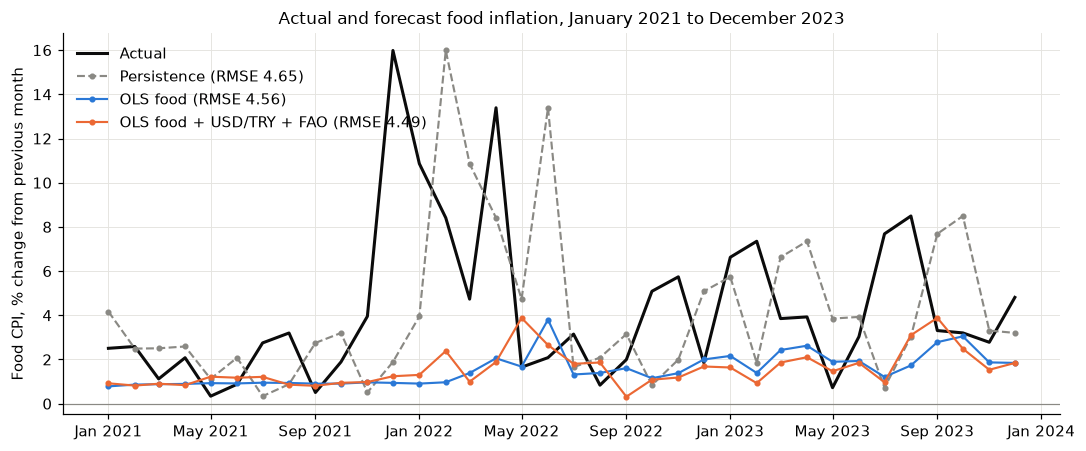

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(forecasts.index, forecasts["actual"], color="#0b0b0b", linewidth=2, label="Actual")
for method, color, style in zip(METHODS, [GREY, BLUE, ORANGE], ["--", "-", "-"]):
    ax.plot(forecasts.index, forecasts[method], color=color, linestyle=style, marker="o", markersize=3,
            label=f"{method} (RMSE {scores.loc[method, 'RMSE (pp)']:.2f})")
ax.axhline(0, color=GREY, linewidth=0.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Food CPI, % change from previous month")
ax.set_title("Actual and forecast food inflation, January 2021 to December 2023")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

**Figure 1.** Each forecast applies the two-month timing rule to the revised snapshot. RMSE is in percentage points.

## Interpretation

This is a development backtest on 2021–2023. A later evaluation will test whether the result holds in the reserved months.

- **RMSE:** 4.65 pp for persistence, 4.56 for OLS on food and 4.49 with USD/TRY and FAO added. Adding the two indicators reduces RMSE by about 0.07 pp relative to the food-only model.
- **MAE:** the ranking changes. OLS on food is lowest at 2.98 pp. Adding USD/TRY and FAO raises MAE to 3.06 pp. Persistence has an MAE of 3.54 pp.
- **Bias:** both regressions forecast too low by about 2.7 pp on average (mean errors −2.72 and −2.69). Most of their training rows come from 2005–2020, when food inflation averaged 0.91% per month, against 4.26% in 2021–2023. Persistence is almost unbiased (−0.03) but repeats each spike two months late. Its February 2022 forecast was 15.98% against an actual 8.41%.
- **Large months:** in December 2021 (actual 15.98%) all three methods missed by 14–15 pp. In April 2022 (13.39%) persistence missed by 4.98 pp and the regressions by 11.3 and 11.5 pp.

### Limits

- **Vintage:** inputs and actuals are the latest revised values, not the figures known at each origin.
- **Release timing:** The backtest uses a fixed availability rule informed by the sources above. The rule approximates historical release timing. USD/TRY uses a two-month lag although one month may have been available.
- **Fixed design:** one lag, no calendar-month terms and an expanding window that starts in 2005. These were not tuned on the forecast months.